## Import Libraries and Configuration Settings

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# !pip install imblearn  # Sudah terinstal di .venv

from src.evaluation import (
    compare_models,
    cross_validate_configs,
    generate_submission,
    save_and_verify_model,
    split_train_validation,
    train_and_evaluate,
    verify_smote_order,
)
from src.models import DEFAULT_KNN_CONFIGS, DEFAULT_NB_CONFIGS, KNN, WideNaiveBayes, get_knn_preprocessing_config
from src.models import DEFAULT_DTL_CONFIGS, C45DecisionTree
from src.preprocess.preprocess import PreprocessingConfig, run_preprocessing
from src.preprocess.nb_features import prepare_nb_features
from src.preprocess.dtl_features import DTL_CATEGORICAL_COLUMNS, prepare_dtl_features

RANDOM_STATE = 824


## Data Understanding

In [ ]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

print(f'Format submisi:\n{sample_submission.head()}')

print(f'Panjang train dataset = {len(train_df)}')
print(f'Panjang test dataset = {len(test_df)}')

train_df.describe()
# test_df.describe()

# print(train_df.head())

Format submisi:
         id  is_canceled
0  5cb6f473            0
1  c06b4ab3            0
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Panjang train dataset = 27373
Panjang test dataset = 6844


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


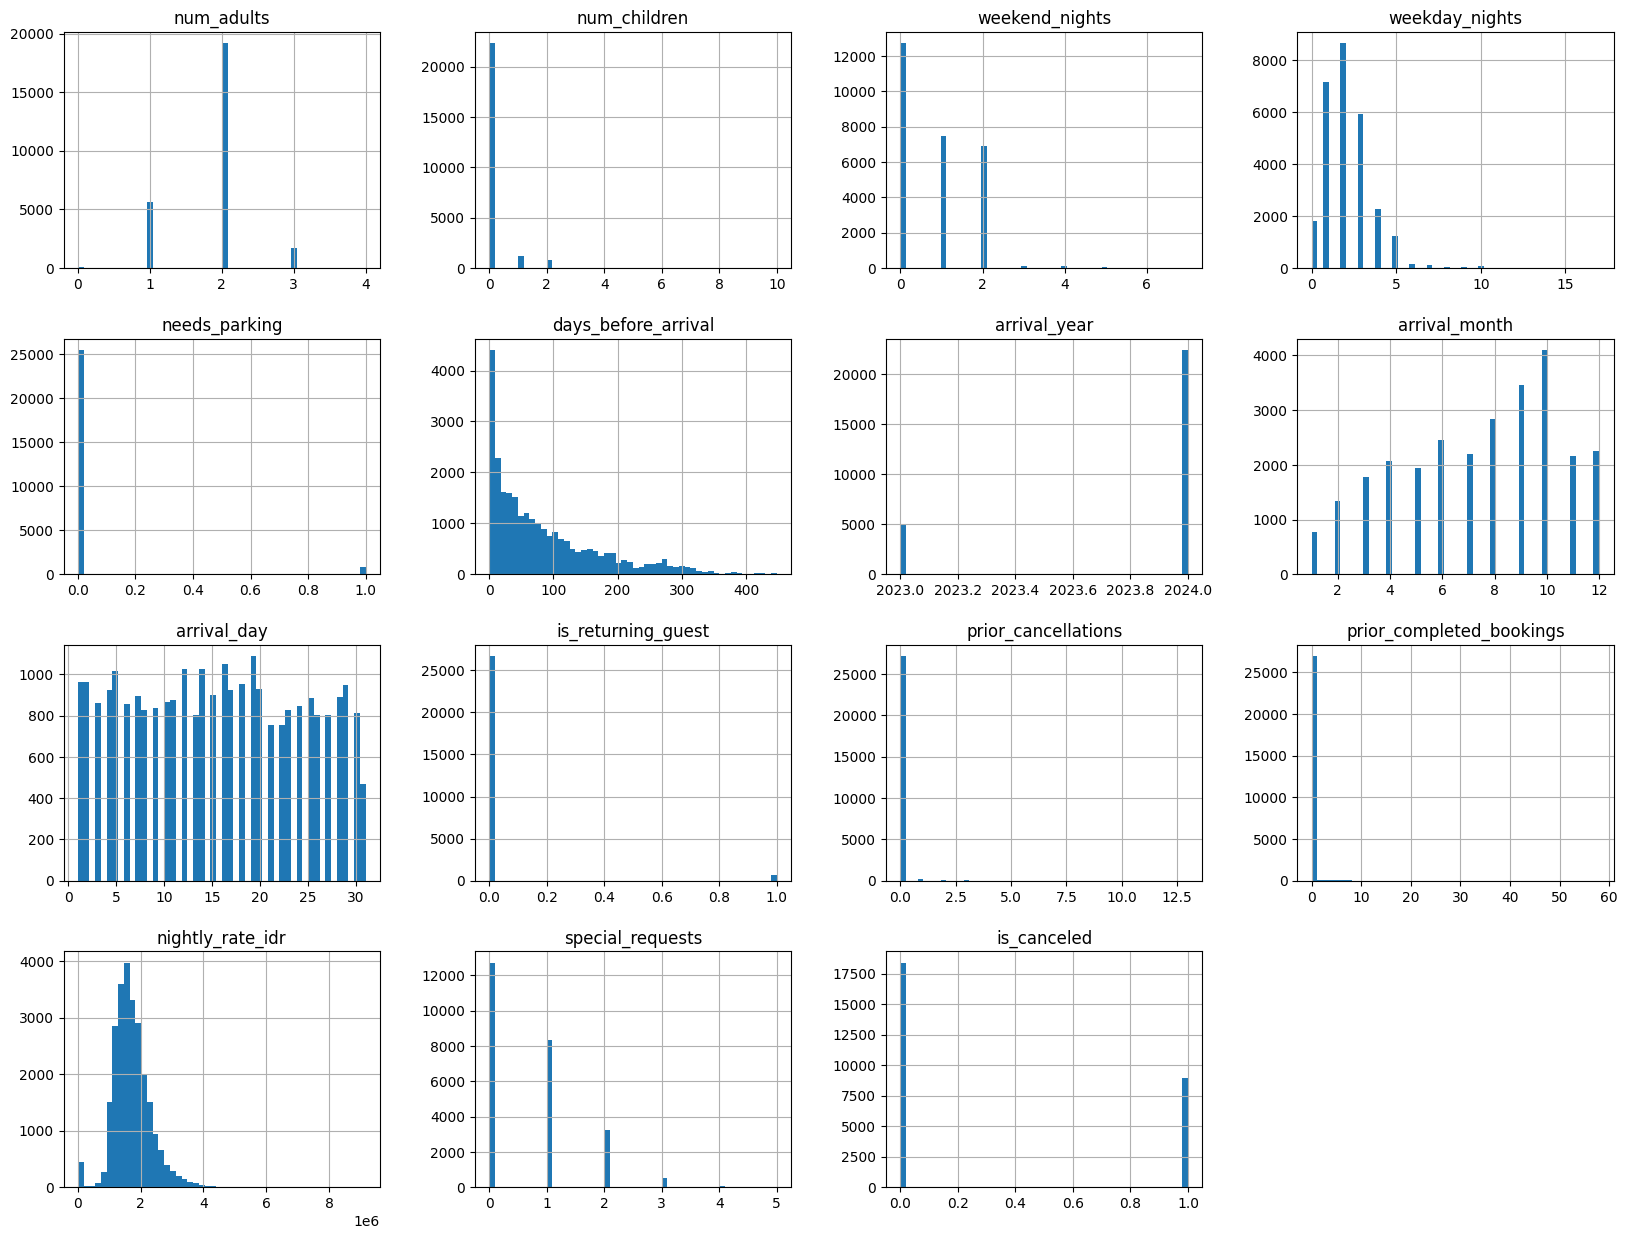

In [3]:
train_df.hist(bins=50, figsize=(20,15))
plt.show()

In [4]:
print('Standard Correlation Coefficient (Pearson\'s r)')

corr_matrix = train_df.corr(numeric_only=True)
corr_matrix['is_canceled'].sort_values(ascending = False)

Standard Correlation Coefficient (Pearson's r)


is_canceled                 1.000000
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
needs_parking              -0.085504
is_returning_guest         -0.107207
special_requests           -0.257996
Name: is_canceled, dtype: float64

## Data Preprocessing (Modular Pipeline)

Tahapan preprocessing dimodularisasi di `src/preprocess/` (`missing.py`, `cleaning.py`, `encoding.py`, `scaling.py`, `balancing.py`, `feature_selection.py`, `reduction.py`) dan dijalankan melalui `src/preprocess/preprocess.py`.


In [ ]:
prep = run_preprocessing(
    train_df,
    test_df,
    config=get_knn_preprocessing_config(random_state=RANDOM_STATE, verbose=True),
)

X_train_pca = prep.X_train
X_test_pca = prep.X_test
y_train_balanced = prep.y_train
cumulative_variance = prep.cumulative_variance


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o", linestyle="--")
plt.axhline(y=0.95, color="r", linestyle="-", label="95% Explained Variance")
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained")
plt.legend()
plt.grid(True)
plt.show()


## Modeling, Validation, and Model Comparison

Setiap model diimplementasikan di `src/models/` dan dievaluasi menggunakan split & 5-fold Stratified CV yang seragam melalui `src/evaluation/`.


In [ ]:
verify_smote_order(prep.X_train_encoded, prep.X_train_balanced, verbose=True)
split_data = split_train_validation(
    prep.X_train,
    prep.y_train,
    is_orig=prep.is_orig,
    test_size=0.15,
    random_state=RANDOM_STATE,
    verbose=True,
)

evaluation_results = []


### Model 1: K-Nearest Neighbors (KNN Scratch)


In [ ]:
best_knn_config, knn_cv_df = cross_validate_configs(
    KNN,
    DEFAULT_KNN_CONFIGS,
    split_data.X_tr,
    split_data.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="KNN",
    verbose=True,
)
display(knn_cv_df)

knn_result = train_and_evaluate(
    KNN(**best_knn_config),
    split_data,
    model_name="KNN",
    config=best_knn_config,
    X_test=prep.X_test,
    plot_cm=True,
)
evaluation_results.append(knn_result)


### Model 2: Naive Bayes (Weighted NB Scratch)

Naive Bayes tidak memakai pipeline scaling/SMOTE/PCA karena ketiganya merusak asumsi independensi dan distribusi fitur NB. Fitur dibuat dengan `prepare_nb_features`, lalu di dalam `WideNaiveBayes` dilakukan diskritisasi MDL, fitur gabungan, dan pembobotan per fitur. Detail eksperimen ada di `notebooks/naive_bayes_experiment.ipynb`.

In [ ]:
nb_split = split_train_validation(
    prepare_nb_features(train_df, extra=True, flags=True).values,
    train_df['is_canceled'].values,
    test_size=0.15,
    random_state=RANDOM_STATE,
)

best_nb_config, nb_cv_df = cross_validate_configs(
    WideNaiveBayes,
    DEFAULT_NB_CONFIGS,
    nb_split.X_tr,
    nb_split.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="Naive Bayes",
)
display(nb_cv_df)

nb_result = train_and_evaluate(
    WideNaiveBayes(**best_nb_config),
    nb_split,
    model_name="Naive Bayes",
    config=best_nb_config,
    X_test=prepare_nb_features(test_df, extra=True, flags=True).values,
)
evaluation_results.append(nb_result)

### Model 3: Decision Tree Learning (C4.5 Scratch)

Fitur DTL dibuat dengan prepare_dtl_features. Kolom kategori tetap diperlakukan
sebagai kategori oleh pohon. Eksperimen serta pembanding scikit-learn ada
di notebooks/dtl_experiment.ipynb.

In [ ]:
X_dtl = prepare_dtl_features(train_df.drop_duplicates())
X_dtl_test = prepare_dtl_features(test_df)
dtl_categorical_indices = [
    X_dtl.columns.get_loc(column) for column in DTL_CATEGORICAL_COLUMNS
]
dtl_configs = [
    dict(config, categorical_features=dtl_categorical_indices)
    for config in DEFAULT_DTL_CONFIGS
]
dtl_split = split_train_validation(
    X_dtl.values,
    train_df.drop_duplicates()["is_canceled"].values,
    test_size=0.15,
    random_state=RANDOM_STATE,
)

best_dtl_config, dtl_cv_df = cross_validate_configs(
    C45DecisionTree,
    dtl_configs,
    dtl_split.X_tr,
    dtl_split.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="DTL",
)
display(dtl_cv_df)

dtl_result = train_and_evaluate(
    C45DecisionTree(**best_dtl_config),
    dtl_split,
    model_name="DTL",
    config=best_dtl_config,
    X_test=X_dtl_test.values,
)
evaluation_results.append(dtl_result)

### Model Comparison


In [ ]:
comparison_df = compare_models(evaluation_results)
display(comparison_df)

best_result = max(evaluation_results, key=lambda item: item["macro_f1"])
print(f"Best model: {best_result['model_name']} (Macro F1 = {best_result['macro_f1']:.5f})")


## Submission


In [ ]:
best_slug = best_result["model_name"].lower().replace(" ", "_")
model_filename = f"output/{best_slug}.pkl"
submission_csv_path = f"output/submission_{best_slug}.csv"
best_X_test = (
    best_result["X_test"]
    if best_result.get("X_test") is not None
    else prep.X_test
)

loaded_best_model = save_and_verify_model(best_result["model"], model_filename, verbose=True)
submission = generate_submission(
    loaded_best_model,
    best_X_test,
    test_df["id"],
    sample_submission,
    submission_csv_path,
    random_state=RANDOM_STATE,
    verbose=True,
)
display(submission.head())


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=f5928910-4999-4958-8a98-3bd08002b179' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>